# Phase 1 — Bank term-deposit data understanding and EDA
This notebook inspects the supplied data without training models or applying preprocessing. Observed findings are descriptive associations, not causal effects. Original rows, categories, and values are retained. Plot-only subsets and bins are explicitly labelled.

## Sources and limitations
Read: `README.md` and `dataset.csv`. **MSI5001 Project Bank Telemarketing.docx was not present in the supplied workspace**; requirements in that brief have not been verified. Add the brief for a follow-up review.
The README describes a Portuguese bank telemarketing dataset, approximately 40,000 records, with 20 predictors and one target. The supplied file actually has 19 predictors and one target. No absent feature is reconstructed or inferred.

## Google Colab loading instructions
Upload this notebook to Colab and run all cells. Upload the original `dataset.csv` when prompted, or set `DATA_PATH` to an existing file. For Drive, first mount it with `from google.colab import drive; drive.mount('/content/drive')`, then set the full path. The README and project brief should also accompany the notebook for review; code execution only needs the CSV. Standard Colab includes pandas, NumPy, Matplotlib, Seaborn and IPython. No installation, model training, encoding, scaling, resampling or data export is performed.


In [1]:
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 30)
DATA_PATH = None  # e.g. '/content/drive/MyDrive/project/dataset.csv'
if DATA_PATH is None:
    candidates = [Path('dataset.csv'), Path('../bank-marketing-ml/dataset.csv'), Path('/workspace/bank-marketing-ml/dataset.csv')]
    DATA_PATH = next((p for p in candidates if p.is_file()), None)
if DATA_PATH is None:
    from google.colab import files
    uploaded = files.upload()
    if 'dataset.csv' not in uploaded:
        raise FileNotFoundError('Please upload the original dataset.csv')
    DATA_PATH = Path('dataset.csv')
DATA_PATH = Path(DATA_PATH)
source_sha256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
df = pd.read_csv(DATA_PATH, sep=None, engine='python')
raw_snapshot = df.copy(deep=True)  # verification only; no treatments applied
print('Source:', DATA_PATH, '\nSHA-256:', source_sha256)
print('Shape:', df.shape, '\nColumns:', df.columns.tolist())
display(df.head(8))
display(df.sample(5, random_state=5001))
display(df.dtypes.rename('Python dtype').to_frame())
df.info()


Source: /workspace/bank-marketing-ml/dataset.csv 
SHA-256: 81fd5eb4b659dddbc704edd90376c32714c3f6a43b887cb686762903bc793f0d
Shape: (41188, 20) 
Columns: ['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 20 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  int64  
 5   housing         41188 non-null  int64  
 6   loan            41188 non-null  int64  
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_o

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,0,0,0,telephone,may,mon,261,1,999,0,1.1,93.994,-36.4,4.857,5191.0,0
1,57,services,married,high.school,-1,0,0,telephone,may,mon,149,1,999,0,1.1,93.994,-36.4,4.857,5191.0,0
2,37,services,married,high.school,0,1,0,telephone,may,mon,226,1,999,0,1.1,93.994,-36.4,4.857,5191.0,0
3,40,admin.,married,basic.6y,0,0,0,telephone,may,mon,151,1,999,0,1.1,93.994,-36.4,4.857,5191.0,0
4,56,services,married,high.school,0,0,1,telephone,may,mon,307,1,999,0,1.1,93.994,-36.4,4.857,5191.0,0
5,45,services,married,basic.9y,-1,0,0,telephone,may,mon,198,1,999,0,1.1,93.994,-36.4,4.857,5191.0,0
6,59,admin.,married,professional.course,0,0,0,telephone,may,mon,139,1,999,0,1.1,93.994,-36.4,4.857,5191.0,0
7,41,blue-collar,married,unknown,-1,0,0,telephone,may,mon,217,1,999,0,1.1,93.994,-36.4,4.857,5191.0,0


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
21780,58,blue-collar,married,basic.9y,-1,1,0,cellular,aug,wed,127,1,999,0,1.4,93.444,-36.1,4.964,5228.1,0
38119,60,retired,divorced,professional.course,0,1,0,cellular,sep,thu,63,1,999,2,-3.4,92.379,-29.8,0.743,5017.5,0
28666,27,blue-collar,single,basic.4y,0,1,0,cellular,apr,thu,240,1,999,0,-1.8,93.075,-47.1,1.410,5099.1,0
20212,35,technician,married,professional.course,0,1,0,cellular,aug,mon,185,1,999,0,1.4,93.444,-36.1,4.965,5228.1,0
37490,34,self-employed,married,university.degree,0,0,0,cellular,aug,thu,78,2,999,0,-2.9,92.201,-31.4,0.873,5076.2,0


,Python dtype
age,int64
job,object
marital,object
education,object
default,int64
housing,int64
loan,int64
contact,object
month,object
day_of_week,object


## Feature meanings and semantic types
Integer codes do not make `default`, `housing`, `loan` or `y` quantitative. Month/day are calendar categories, not measured intervals; education has partial ordering but professional and university tracks need an agreed representation. Counts are numerical discrete variables. `pdays` is a duration with a structural sentinel. Negative economic values can be legitimate index/rate observations, not missingness.
README: `marital=divorced` also includes widowed. Campaign counts include the last contact. Indicator frequencies are quarterly for employment variation/number employed, monthly for price/confidence, and daily for Euribor. Units beyond those descriptions are not supplied; do not interpret `nr.employed` as an individual client attribute.


In [2]:
categorical = ['job','marital','education','default','housing','loan','contact','month','day_of_week']
numerical = ['age','duration','campaign','pdays','previous','emp.var.rate','cons.price.idx','cons.conf.idx','euribor3m','nr.employed']
meaning = {
'age':'Age in years; quantitative', 'job':'Nominal occupation', 'marital':'Nominal marital status; divorced includes widowed',
'education':'Education categories; partial ordering', 'default':'Credit default status: 0 no, 1 yes, -1 unknown',
'housing':'Housing loan: 0 no, 1 yes, -1 unknown','loan':'Personal loan: 0 no, 1 yes, -1 unknown',
'contact':'Communication channel','month':'Last contact month; calendar category','day_of_week':'Last contact weekday; calendar category',
'duration':'Last call seconds; unavailable before call','campaign':'Current campaign contacts, including last; discrete count',
'pdays':'Previous campaign recency in days; 999 = not previously contacted','previous':'Prior campaign contacts; discrete count',
'emp.var.rate':'Employment variation rate; quarterly','cons.price.idx':'Consumer price index; monthly','cons.conf.idx':'Consumer confidence index; monthly',
'euribor3m':'3-month Euribor rate; daily','nr.employed':'Employment indicator; quarterly','y':'Target: 0 no, 1 yes, -1 unknown if present'}
assert set(df.columns) == set(categorical + numerical + ['y']), 'Review unexpected schema before continuing'
feature_dictionary = pd.DataFrame([{'column':c,'dtype':str(df[c].dtype),'semantic_type':'target categorical' if c=='y' else ('categorical' if c in categorical else 'numerical'),'meaning':meaning[c]} for c in df])
display(feature_dictionary)
display(df[numerical].describe(percentiles=[.01,.25,.5,.75,.95,.99]).T)


,column,dtype,semantic_type,meaning
0,age,int64,numerical,Age in years; quantitative
1,job,object,categorical,Nominal occupation
2,marital,object,categorical,Nominal marital status; divorced includes widowed
3,education,object,categorical,Education categories; partial ordering
4,default,int64,categorical,"Credit default status: 0 no, 1 yes, -1 unknown"
5,housing,int64,categorical,"Housing loan: 0 no, 1 yes, -1 unknown"
6,loan,int64,categorical,"Personal loan: 0 no, 1 yes, -1 unknown"
7,contact,object,categorical,Communication channel
8,month,object,categorical,Last contact month; calendar category
9,day_of_week,object,categorical,Last contact weekday; calendar category


,count,mean,std,min,1%,25%,50%,75%,95%,99%,max
age,41188.0,40.024060,10.421250,17.000,23.00000,32.000,38.000,47.000,58.000,71.000,98.000
duration,41188.0,258.285010,259.279249,0.000,11.00000,102.000,180.000,319.000,752.650,1271.130,4918.000
campaign,41188.0,2.567593,2.770014,1.000,1.00000,1.000,2.000,3.000,7.000,14.000,56.000
pdays,41188.0,962.475454,186.910907,0.000,3.00000,999.000,999.000,999.000,999.000,999.000,999.000
previous,41188.0,0.172963,0.494901,0.000,0.00000,0.000,0.000,0.000,1.000,2.000,7.000
emp.var.rate,41188.0,0.081886,1.570960,-3.400,-3.40000,-1.800,1.100,1.400,1.400,1.400,1.400
cons.price.idx,41188.0,93.575664,0.578840,92.201,92.20100,93.075,93.749,93.994,94.465,94.465,94.767
cons.conf.idx,41188.0,-40.502600,4.628198,-50.800,-49.50000,-42.700,-41.800,-36.400,-33.600,-26.900,-26.900
euribor3m,41188.0,3.621291,1.734447,0.634,0.65848,1.344,4.857,4.961,4.966,4.968,5.045
nr.employed,41188.0,5167.035911,72.251528,4963.600,4963.60000,5099.100,5191.000,5228.100,5228.100,5228.100,5228.100


## Target distribution
**Observed:** 36,548 no (88.7346%) and 4,640 yes (11.2654%); no unknown target labels. A majority-only prediction would have 88.73% accuracy, illustrating why accuracy alone would be inadequate; no such model is trained here. **Hypothesis:** class imbalance may complicate minority-class recall. Treatment and metrics require approval.


,count,percent
y,,
0,36548,88.734583
1,4640,11.265417


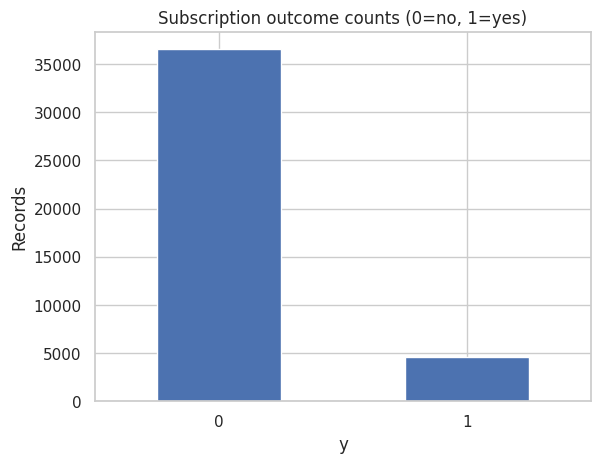

In [3]:
target = df.y.value_counts(dropna=False).sort_index().rename('count').to_frame()
target['percent'] = target['count'] / len(df) * 100
display(target)
ax = target['count'].plot.bar(title='Subscription outcome counts (0=no, 1=yes)', rot=0)
ax.set_ylabel('Records')
plt.show()


## Missingness, unknown categories and special values — every column
Literal nulls, blank strings, textual `unknown`, and numeric sentinel candidates are reported separately. The `-1` and `999` columns below are audits, not a rule that these values always mean missing. README defines `-1` only for loan/default statuses and target, and `999` only for `pdays`. `previous=0` means no prior contacts; `duration=0` means no completed call per README; `pdays=0` is a zero-day interval, not the documented no-contact code. A zero economic rate can be valid. No replacements are applied.
**Observed:** no pandas-null values. Unknown job=330, marital=80, education=1,731; default=-1 in 8,597 rows; housing and loan=-1 in 990 rows each. `pdays=999` occurs in 39,673 rows (96.322%). The main missing-information burden is default status. These are retained.


In [4]:
audit = []
for c in df:
    s = df[c]
    textual = s.astype('string')
    audit.append({'column':c,'null_n':int(s.isna().sum()),'blank_n':int(textual.str.strip().eq('').sum()),
                  'unknown_text_n':int(textual.str.strip().str.lower().eq('unknown').sum()),
                  'minus1_n':int(s.eq(-1).sum()),'value999_n':int(s.eq(999).sum()),'zero_n':int(s.eq(0).sum()),
                  'unique_n':s.nunique(dropna=False), 'README_interpretation':meaning[c]})
audit = pd.DataFrame(audit)
for k in ['null_n','blank_n','unknown_text_n','minus1_n','value999_n']:
    audit[k.replace('_n','_percent')] = audit[k]/len(df)*100
display(audit)
for c in categorical:
    print(c)
    display(df[c].value_counts(dropna=False).rename('count').to_frame().assign(percent=lambda t:t['count']/len(df)*100))


job
marital
education
default
housing
loan
contact
month
day_of_week


,column,null_n,blank_n,unknown_text_n,minus1_n,value999_n,zero_n,unique_n,README_interpretation,null_percent,blank_percent,unknown_text_percent,minus1_percent,value999_percent
0,age,0,0,0,0,0,0,78,Age in years; quantitative,0.0,0.0,0.000000,0.000000,0.000000
1,job,0,0,330,0,0,0,12,Nominal occupation,0.0,0.0,0.801204,0.000000,0.000000
2,marital,0,0,80,0,0,0,4,Nominal marital status; divorced includes widowed,0.0,0.0,0.194231,0.000000,0.000000
3,education,0,0,1731,0,0,0,8,Education categories; partial ordering,0.0,0.0,4.202680,0.000000,0.000000
4,default,0,0,0,8597,0,32588,3,"Credit default status: 0 no, 1 yes, -1 unknown",0.0,0.0,0.000000,20.872584,0.000000
5,housing,0,0,0,990,0,18622,3,"Housing loan: 0 no, 1 yes, -1 unknown",0.0,0.0,0.000000,2.403613,0.000000
6,loan,0,0,0,990,0,33950,3,"Personal loan: 0 no, 1 yes, -1 unknown",0.0,0.0,0.000000,2.403613,0.000000
7,contact,0,0,0,0,0,0,2,Communication channel,0.0,0.0,0.000000,0.000000,0.000000
8,month,0,0,0,0,0,0,10,Last contact month; calendar category,0.0,0.0,0.000000,0.000000,0.000000
9,day_of_week,0,0,0,0,0,0,5,Last contact weekday; calendar category,0.0,0.0,0.000000,0.000000,0.000000


,count,percent
job,,
admin.,10422,25.303486
blue-collar,9254,22.467709
technician,6743,16.371273
services,3969,9.636302
management,2924,7.099155
retired,1720,4.175974
entrepreneur,1456,3.535010
self-employed,1421,3.450034
housemaid,1060,2.573565


,count,percent
marital,,
married,24928,60.522482
single,11568,28.085850
divorced,4612,11.197436
unknown,80,0.194231


,count,percent
education,,
university.degree,12168,29.542585
high.school,9515,23.101389
basic.9y,6045,14.676605
professional.course,5243,12.729436
basic.4y,4176,10.138875
basic.6y,2292,5.564728
unknown,1731,4.202680
illiterate,18,0.043702


...

,count,percent
housing,,
1,21576,52.384190
0,18622,45.212198
-1,990,2.403613


,count,percent
loan,,
0,33950,82.426920
1,6248,15.169467
-1,990,2.403613


,count,percent
contact,,
cellular,26144,63.474798
telephone,15044,36.525202


,count,percent
month,,
may,13769,33.429640
jul,7174,17.417694
aug,6178,14.999514
jun,5318,12.911528
nov,4101,9.956784
apr,2632,6.390211
oct,718,1.743226
sep,570,1.383898
mar,546,1.325629


,count,percent
day_of_week,,
thu,8623,20.935709
mon,8514,20.671069
wed,8134,19.748470
tue,8090,19.641643
fri,7827,19.003108


## Duplicates, domain checks and unusual values
**Observed:** 12 duplicate rows beyond first occurrences. Duplicate records cannot be confirmed as duplicate people: no customer identifier is supplied. Age ranges 17–98, campaign 1–56, duration 0–4,918 seconds and previous 0–7. Extremes are review flags, not proven errors. Four zero-duration records all have y=0, agreeing with the README.
Only three records have default=1 and 18 have education=illiterate; rates for tiny groups are unstable. January/February are absent despite being valid README month categories; this is coverage, not proof of corruption.
`previous>0` with `pdays=999` appears in 4,110 rows. The literal definitions suggest a history inconsistency, but campaign-history scope might explain it; request clarification before treating either field as erroneous. No previous=0 rows have a non-sentinel pdays. No outcome conflicts were found among identical predictor records.


In [5]:
expected = {
'job':set(['admin.','blue-collar','entrepreneur','housemaid','management','retired','self-employed','services','student','technician','unemployed','unknown']),
'marital':set(['divorced','married','single','unknown']),
'education':set(['basic.4y','basic.6y','basic.9y','high.school','illiterate','professional.course','university.degree','unknown']),
'default':{-1,0,1},'housing':{-1,0,1},'loan':{-1,0,1},'y':{-1,0,1},
'contact':{'cellular','telephone'},'month':set('jan feb mar apr may jun jul aug sep oct nov dec'.split()),'day_of_week':set('mon tue wed thu fri'.split())}
display(pd.DataFrame([{'column':c,'undocumented_values':sorted(set(df[c].dropna())-allowed), 'documented_but_absent':sorted(allowed-set(df[c].dropna()))} for c,allowed in expected.items()]))
print('Duplicates beyond first:', df.duplicated().sum())
print('All records in duplicate groups:', df.duplicated(keep=False).sum())
display(df.loc[df.duplicated(keep=False)].head(10))
print('Identical-predictor groups with conflicting y:', df.groupby([c for c in df if c!='y'],dropna=False).y.nunique().gt(1).sum())
checks = {'age <= 0':df.age.le(0), 'negative duration':df.duration.lt(0), 'campaign < 1':df.campaign.lt(1),
'negative previous':df.previous.lt(0), 'negative pdays':df.pdays.lt(0),
'previous=0 but actual recency':df.previous.eq(0)&df.pdays.ne(999),
'previous>0 but pdays=999':df.previous.gt(0)&df.pdays.eq(999)}
display(pd.Series({k:int(v.sum()) for k,v in checks.items()},name='flagged_records').to_frame())
display(pd.crosstab(df.duration.eq(0).rename('duration_is_zero'), df.y))
print('Housing/loan unknown flags match on all rows:',df.housing.eq(-1).equals(df.loan.eq(-1)))
# IQR flags are descriptive only; no outlier removal.
q1,q3=df[numerical].quantile(.25),df[numerical].quantile(.75)
iqr=q3-q1
flags=((df[numerical]<q1-1.5*iqr)|(df[numerical]>q3+1.5*iqr)).sum()
display(flags.rename('IQR_flag_count').to_frame())


Duplicates beyond first: 12
All records in duplicate groups: 24
Identical-predictor groups with conflicting y: 0
Housing/loan unknown flags match on all rows: True


,column,undocumented_values,documented_but_absent
0,job,[],[]
1,marital,[],[]
2,education,[],[]
3,default,[],[]
4,housing,[],[]
5,loan,[],[]
6,y,[],[-1]
7,contact,[],[]
8,month,[],"[feb, jan]"
9,day_of_week,[],[]


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
1265,39,blue-collar,married,basic.6y,0,0,0,telephone,may,thu,124,1,999,0,1.1,93.994,-36.4,4.855,5191.0,0
1266,39,blue-collar,married,basic.6y,0,0,0,telephone,may,thu,124,1,999,0,1.1,93.994,-36.4,4.855,5191.0,0
12260,36,retired,married,unknown,0,0,0,telephone,jul,thu,88,1,999,0,1.4,93.918,-42.7,4.966,5228.1,0
12261,36,retired,married,unknown,0,0,0,telephone,jul,thu,88,1,999,0,1.4,93.918,-42.7,4.966,5228.1,0
14155,27,technician,single,professional.course,0,0,0,cellular,jul,mon,331,2,999,0,1.4,93.918,-42.7,4.962,5228.1,0
14234,27,technician,single,professional.course,0,0,0,cellular,jul,mon,331,2,999,0,1.4,93.918,-42.7,4.962,5228.1,0
16819,47,technician,divorced,high.school,0,1,0,cellular,jul,thu,43,3,999,0,1.4,93.918,-42.7,4.962,5228.1,0
16956,47,technician,divorced,high.school,0,1,0,cellular,jul,thu,43,3,999,0,1.4,93.918,-42.7,4.962,5228.1,0
18464,32,technician,single,professional.course,0,1,0,cellular,jul,thu,128,1,999,0,1.4,93.918,-42.7,4.968,5228.1,0
18465,32,technician,single,professional.course,0,1,0,cellular,jul,thu,128,1,999,0,1.4,93.918,-42.7,4.968,5228.1,0


,flagged_records
age <= 0,0
negative duration,0
campaign < 1,0
negative previous,0
negative pdays,0
previous=0 but actual recency,0
previous>0 but pdays=999,4110


y,0,1
duration_is_zero,,
False,36544,4640
True,4,0


,IQR_flag_count
age,469
duration,2963
campaign,2406
pdays,1515
previous,5625
emp.var.rate,0
cons.price.idx,0
cons.conf.idx,447
euribor3m,0
nr.employed,0


## Numerical distributions and outcomes
Histograms show raw distributions for all numerical features, including the structural pdays spike. Target-stratified boxplots show medians, spread and extremes. Socioeconomic variables have repeated values because they describe shared periods; they are not independent client measurements. IQR flags for pdays are dominated by its sentinel and zero IQR, and must not be read as errors.
Age 17–98 and long calls/high contact counts deserve context checks. **Hypothesis:** age and contact frequency may be associated with subscription through customer mix, selection and campaign strategy; these plots cannot establish an optimal frequency or causal effect.


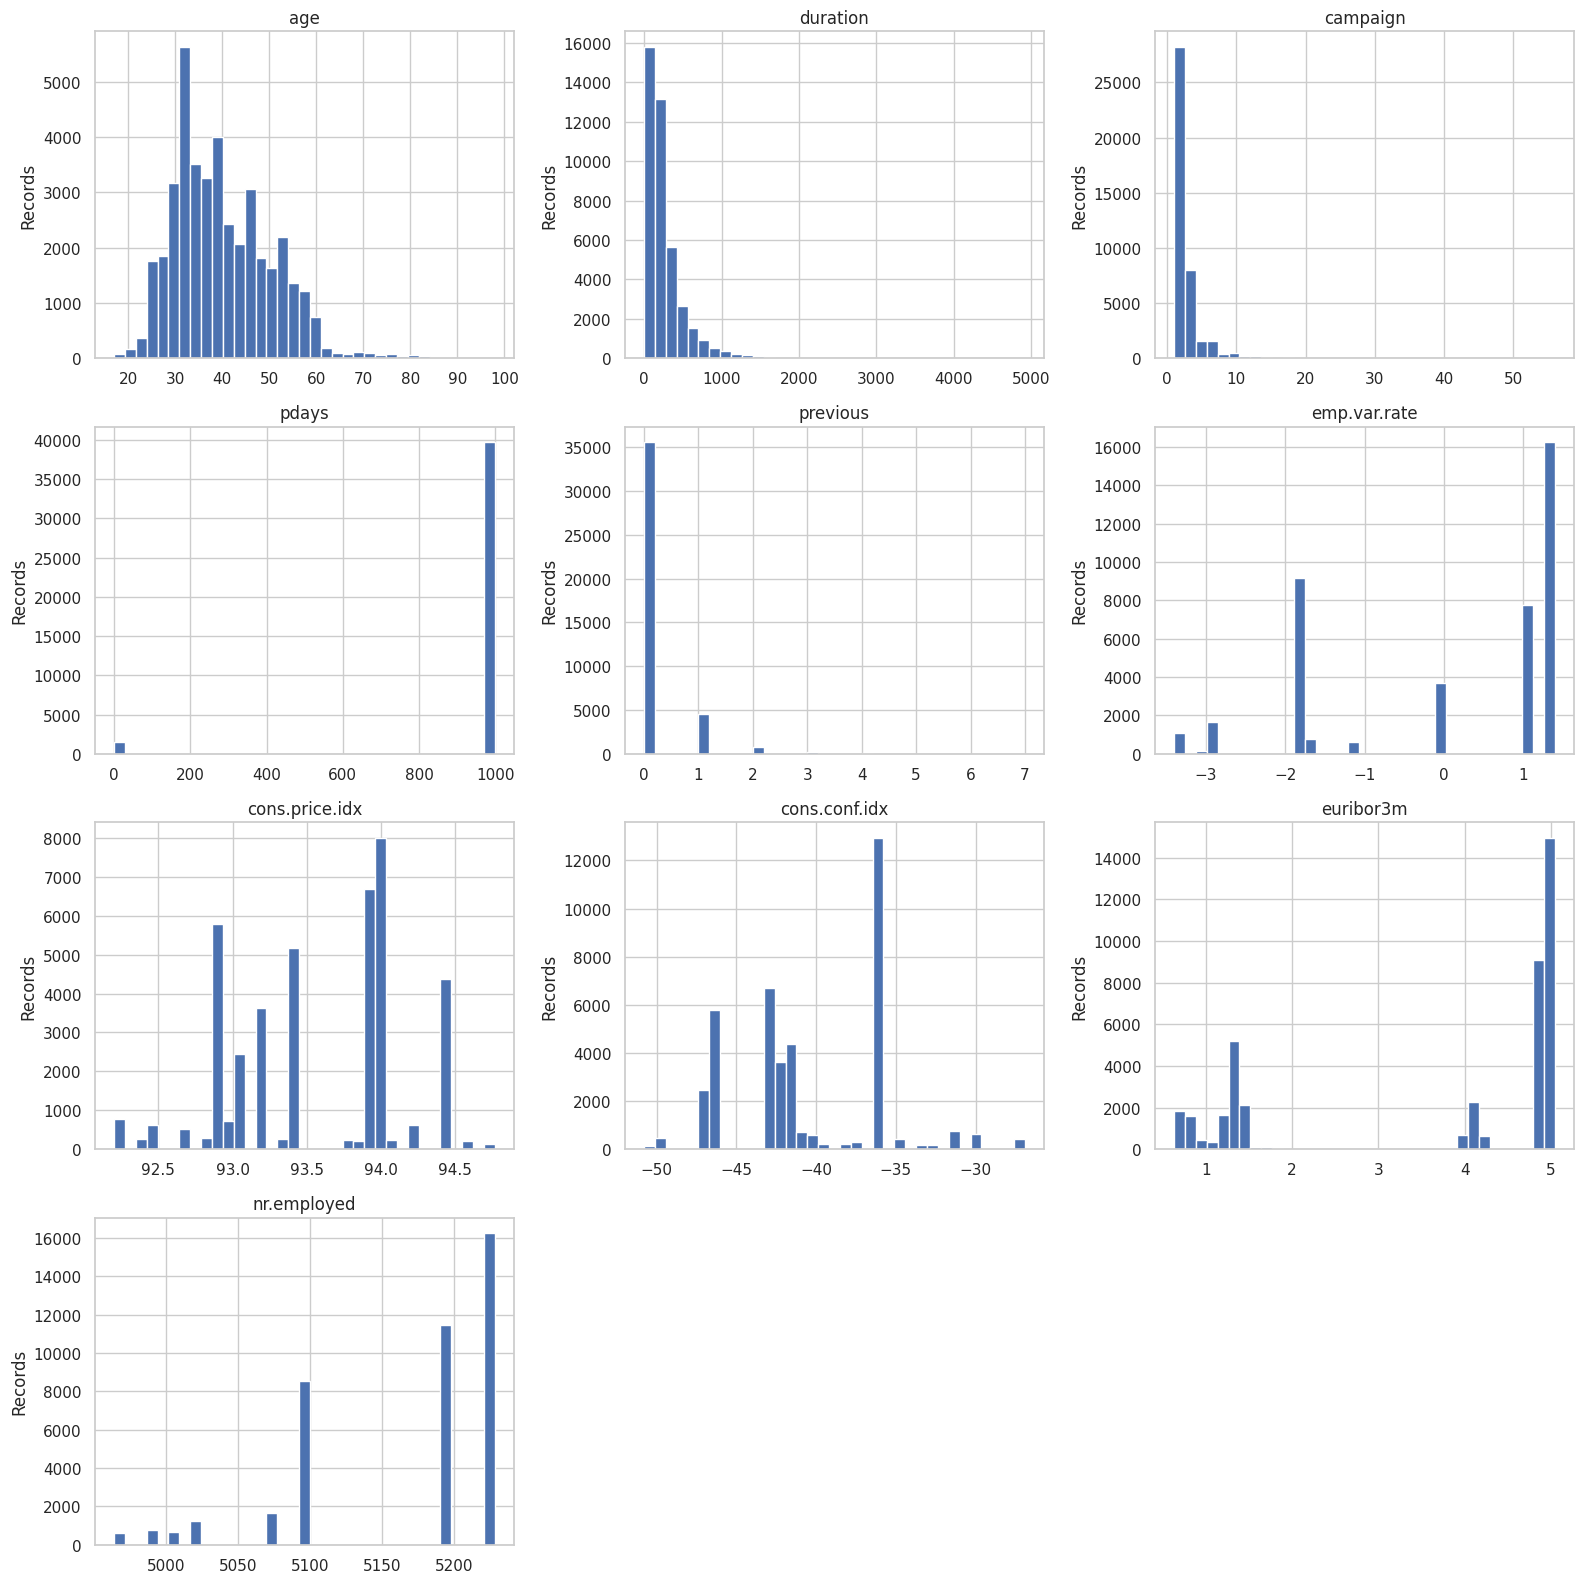

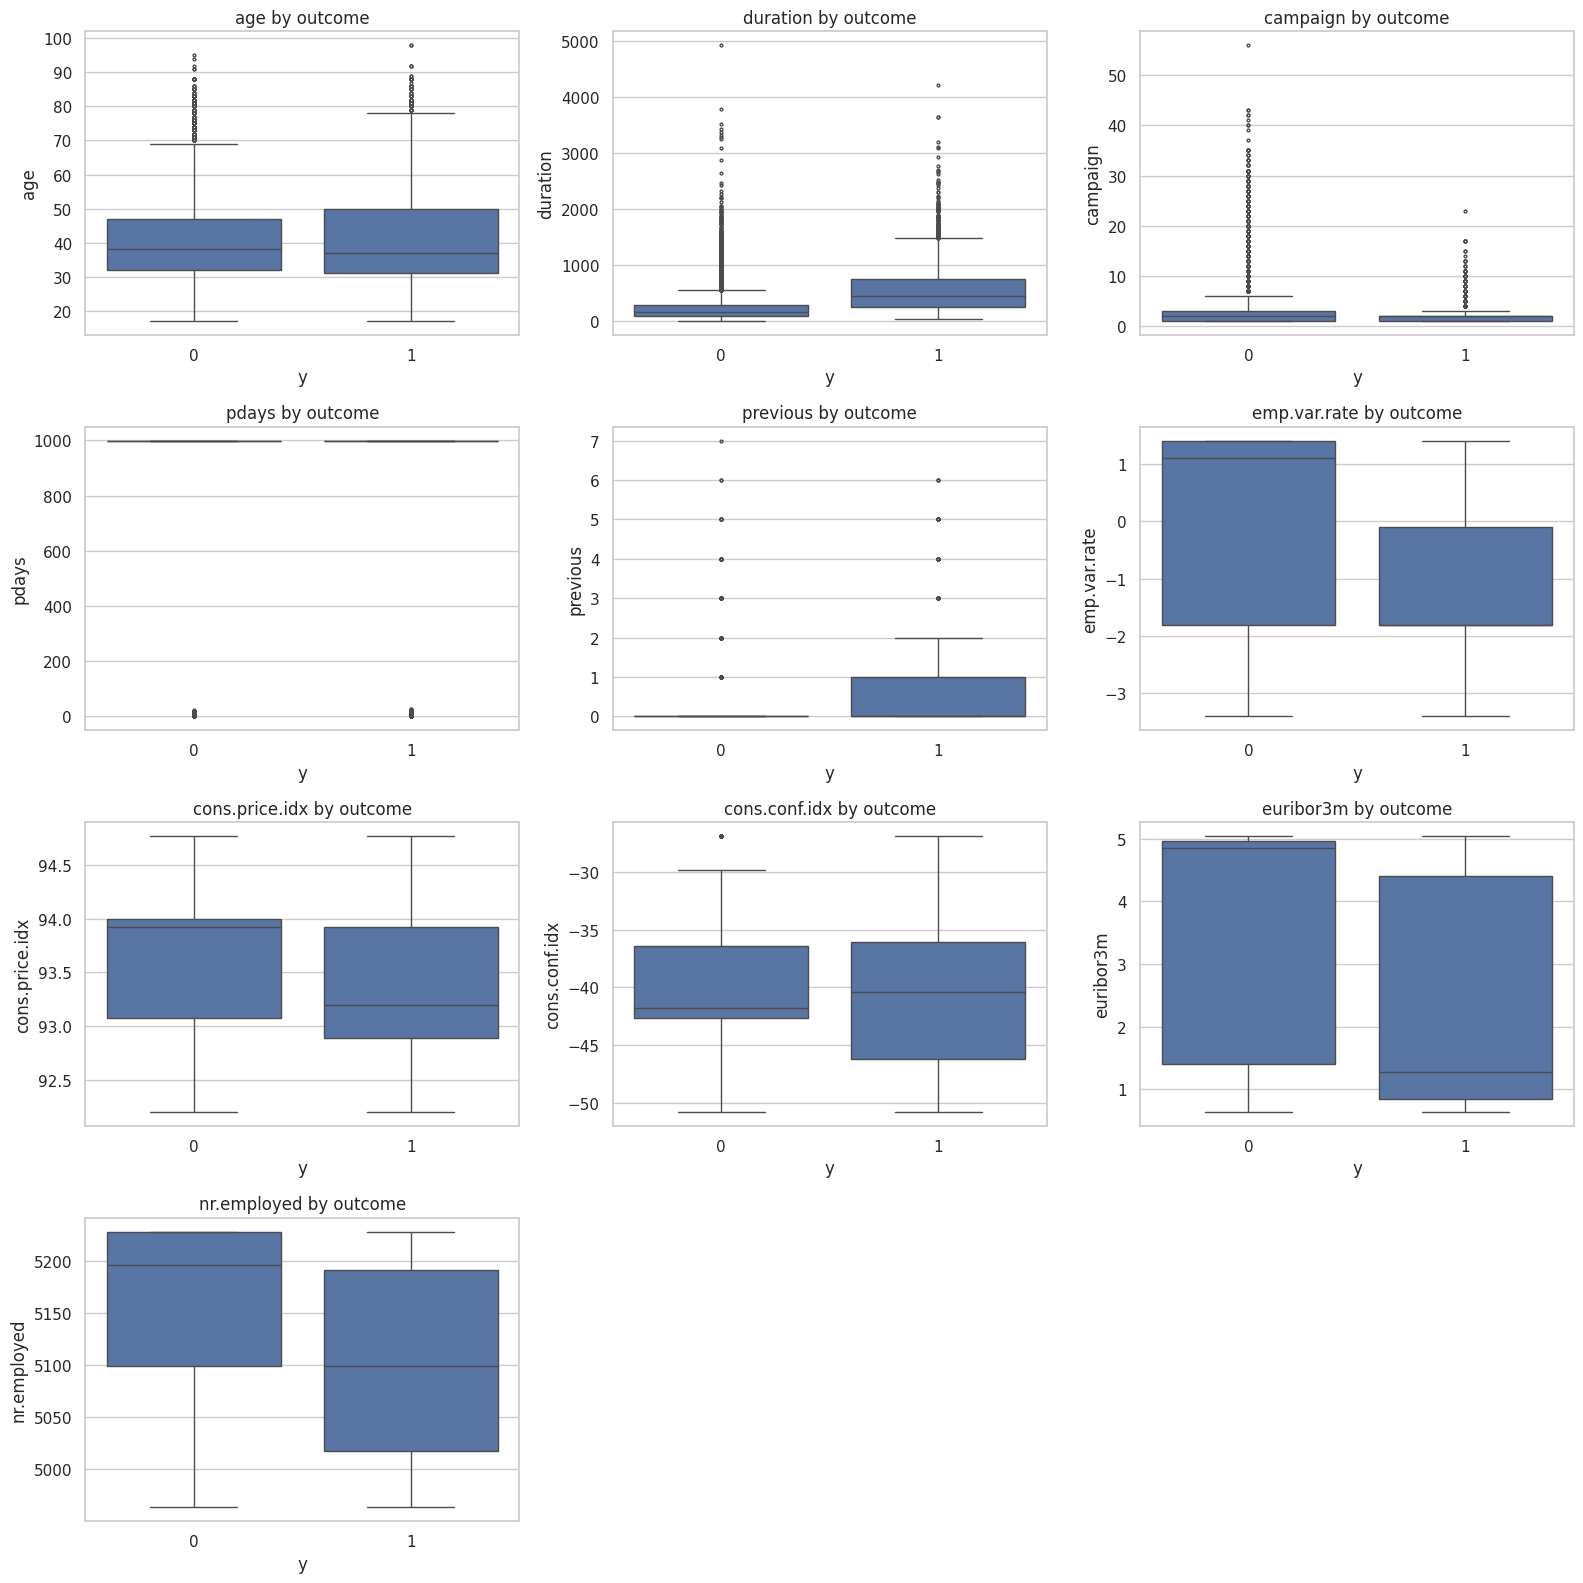

y                                0            1
age            median    38.000000    37.000000
               mean      39.911185    40.913147
               min       17.000000    17.000000
               max       95.000000    98.000000
duration       median   163.500000   449.000000
               mean     220.844807   553.191164
               min        0.000000    37.000000
               max     4918.000000  4199.000000
campaign       median     2.000000     2.000000
               mean       2.633085     2.051724
               min        1.000000     1.000000
               max       56.000000    23.000000
pdays          median   999.000000   999.000000
               mean     984.113878   792.035560
               min        0.000000     0.000000
               max      999.000000   999.000000
previous       median     0.000000     0.000000
               mean       0.132374     0.492672
               min        0.000000     0.000000
               max        7.000000     6.000000
emp.var.rate   median     1.100000    -1.800000
               mean       0.248875    -1.233448
               min       -3.400000    -3.400000
               max        1.400000     1.400000
cons.price.idx median    93.918000    93.200000
               mean      93.603757    93.354386
               min       92.201000    92.201000
               max       94.767000    94.767000
cons.conf.idx  median   -41.800000   -40.400000
               mean     -40.593097   -39.789784
               min      -50.800000   -50.800000
               max      -26.900000   -26.900000
euribor3m      median     4.857000     1.266000
               mean       3.811491     2.123135
               min        0.634000     0.634000
               max        5.045000     5.045000
nr.employed    median  5195.800000  5099.100000
               mean    5176.166600  5095.115991
               min     4963.600000  4963.600000
               max     5228.100000  5228.100000

In [6]:
fig, axes = plt.subplots(4,3,figsize=(16,16))
for ax,c in zip(axes.flat,numerical):
    ax.hist(df[c],bins=35); ax.set_title(c); ax.set_ylabel('Records')
for ax in list(axes.flat)[len(numerical):]: ax.set_visible(False)
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(4,3,figsize=(16,16))
for ax,c in zip(axes.flat,numerical):
    sns.boxplot(data=df,x='y',y=c,ax=ax,showfliers=True,flierprops={'markersize':2})
    ax.set_title(c+' by outcome')
for ax in list(axes.flat)[len(numerical):]: ax.set_visible(False)
plt.tight_layout(); plt.show()
display(df.groupby('y')[numerical].agg(['median','mean','min','max']).T)


## Categorical distributions and subscription rates
Each feature gets a frequency chart and a rate chart, including integer-coded categories. Rates use known targets only (all supplied targets are known). Tables provide group sizes and 95% Wilson intervals to make uncertainty visible. These descriptive intervals assume independent records, which may fail with repeat clients or shared periods. Small groups and many comparisons warrant caution. Education is plotted as categories without choosing an encoding.


,n,subscriptions,rate_percent,lower95_percent,upper95_percent
group,,,,,
admin.,10422,1352,12.972558,12.341084,13.631319
blue-collar,9254,638,6.894316,6.395792,7.428614
entrepreneur,1456,124,8.516484,7.189619,10.061677
housemaid,1060,106,10.000000,8.335901,11.952984
management,2924,328,11.217510,10.124138,12.412655
retired,1720,434,25.232558,23.236583,27.338922
self-employed,1421,149,10.485574,8.997748,12.186473
services,3969,323,8.138070,7.327361,9.029737
student,875,275,31.428571,28.439411,34.580092


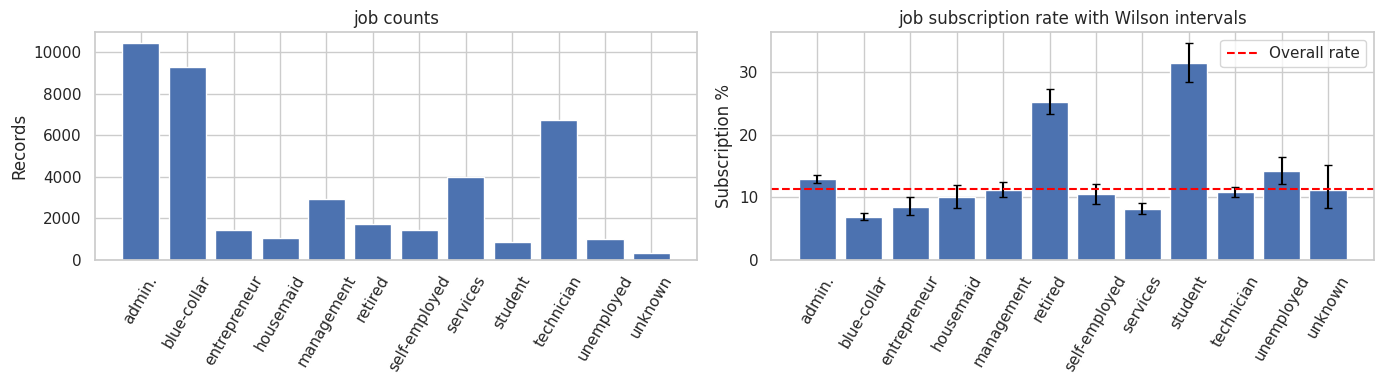

,n,subscriptions,rate_percent,lower95_percent,upper95_percent
group,,,,,
divorced,4612,476,10.320902,9.475627,11.232224
married,24928,2532,10.157253,9.788361,10.538423
single,11568,1620,14.004149,13.383688,14.648510
unknown,80,12,15.000000,8.793954,24.413428


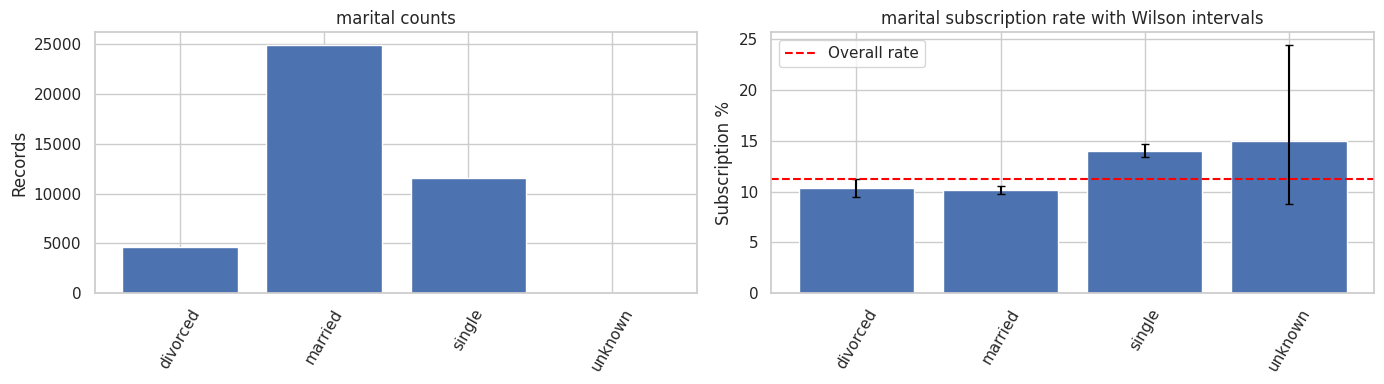

,n,subscriptions,rate_percent,lower95_percent,upper95_percent
group,,,,,
basic.4y,4176,428,10.249042,9.365381,11.205771
basic.6y,2292,188,8.202443,7.147742,9.397023
basic.9y,6045,473,7.824648,7.174105,8.528763
high.school,9515,1031,10.835523,10.226697,11.475960
illiterate,18,4,22.222222,9.000782,45.215026
professional.course,5243,595,11.348465,10.518038,12.235491
university.degree,12168,1670,13.724523,13.124543,14.347402
unknown,1731,251,14.500289,12.920133,16.237664


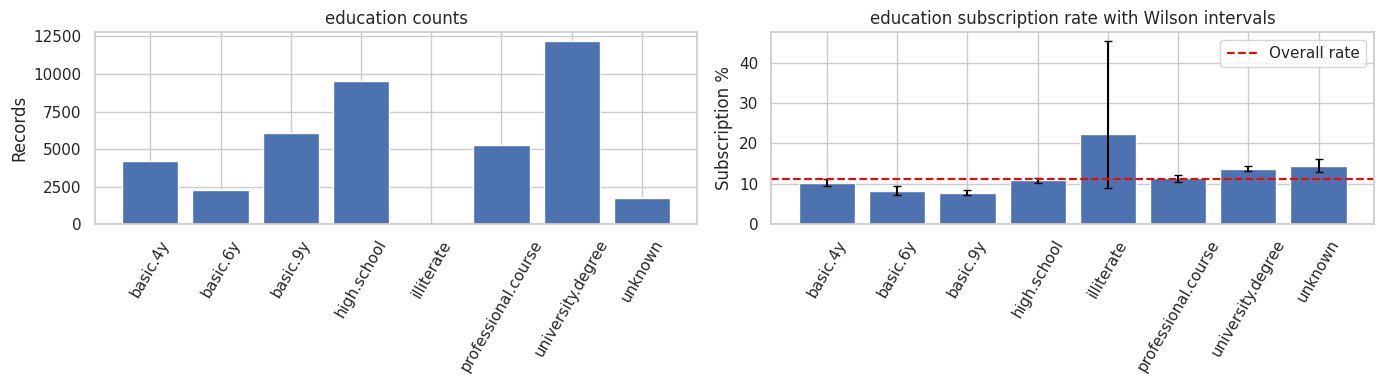

,n,subscriptions,rate_percent,lower95_percent,upper95_percent
group,,,,,
-1,8597,443,5.152960,4.705337,5.640645
0,32588,4197,12.878974,12.519656,13.247043
1,3,0,0.000000,0.000000,56.150608


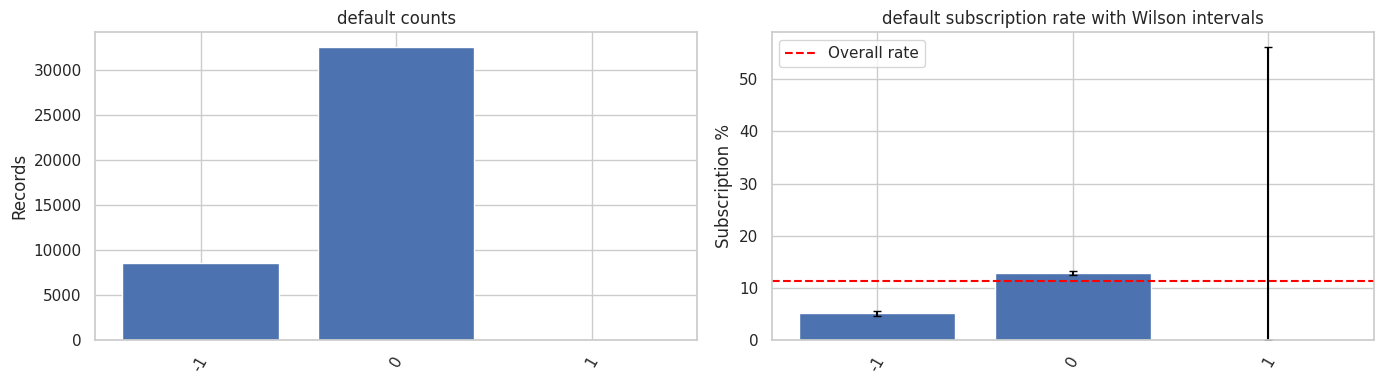

,n,subscriptions,rate_percent,lower95_percent,upper95_percent
group,,,,,
-1,990,107,10.808081,9.023295,12.895852
0,18622,2026,10.879605,10.440409,11.334937
1,21576,2507,11.619392,11.198605,12.053844


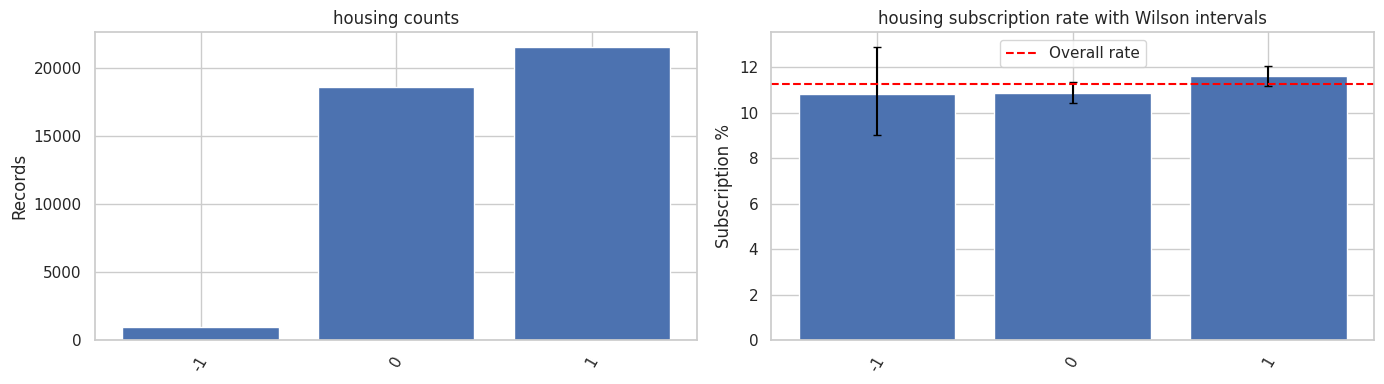

,n,subscriptions,rate_percent,lower95_percent,upper95_percent
group,,,,,
-1,990,107,10.808081,9.023295,12.895852
0,33950,3850,11.340206,11.007276,11.681885
1,6248,683,10.931498,10.181643,11.729366


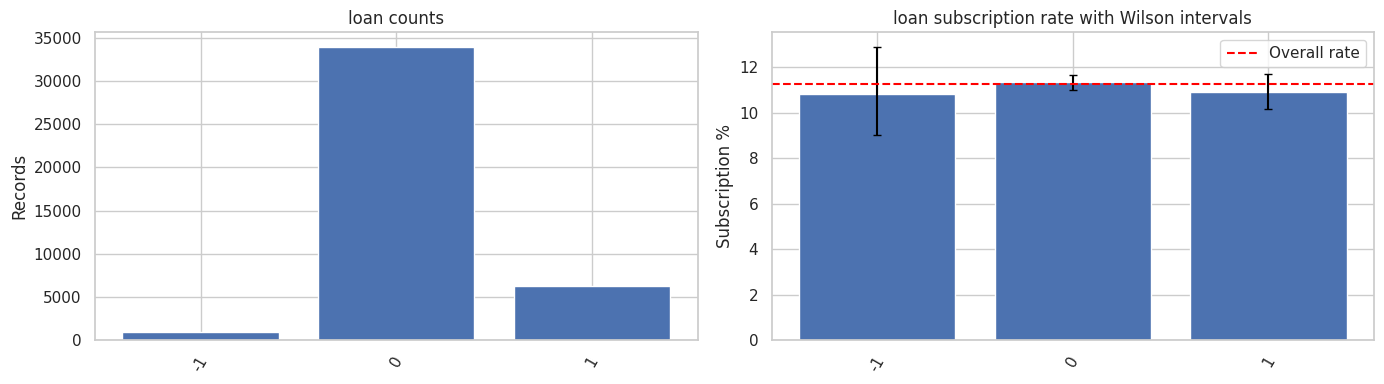

,n,subscriptions,rate_percent,lower95_percent,upper95_percent
group,,,,,
cellular,26144,3853,14.737607,14.313091,15.172484
telephone,15044,787,5.231321,4.886807,5.598694


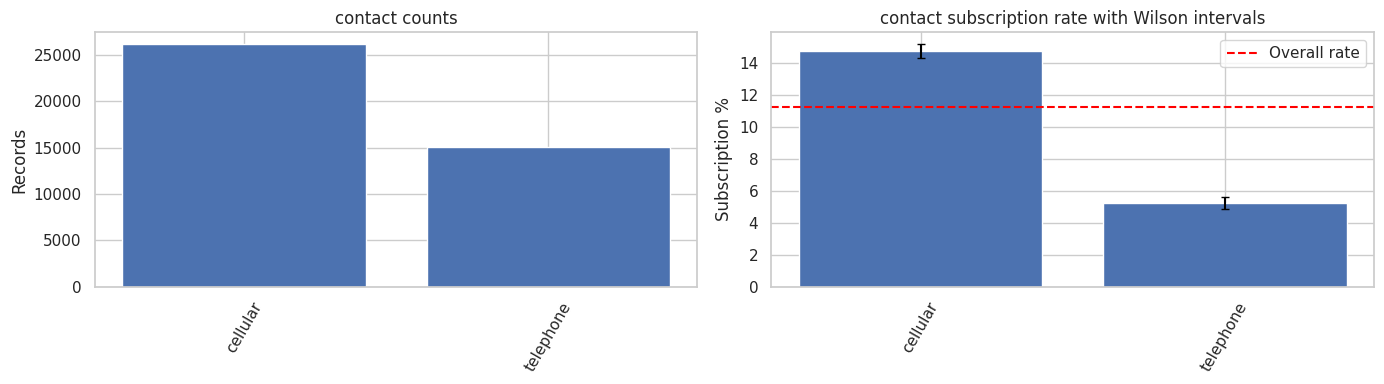

,n,subscriptions,rate_percent,lower95_percent,upper95_percent
group,,,,,
apr,2632,539,20.478723,18.980550,22.062949
aug,6178,655,10.602137,9.858766,11.394473
dec,182,89,48.901099,41.736745,56.110884
jul,7174,649,9.046557,8.404507,9.732443
jun,5318,559,10.511470,9.715457,11.364494
mar,546,276,50.549451,46.366526,54.724697
may,13769,886,6.434745,6.036920,6.856872
nov,4101,416,10.143867,9.256816,11.105520
oct,718,315,43.871866,40.284250,47.524709


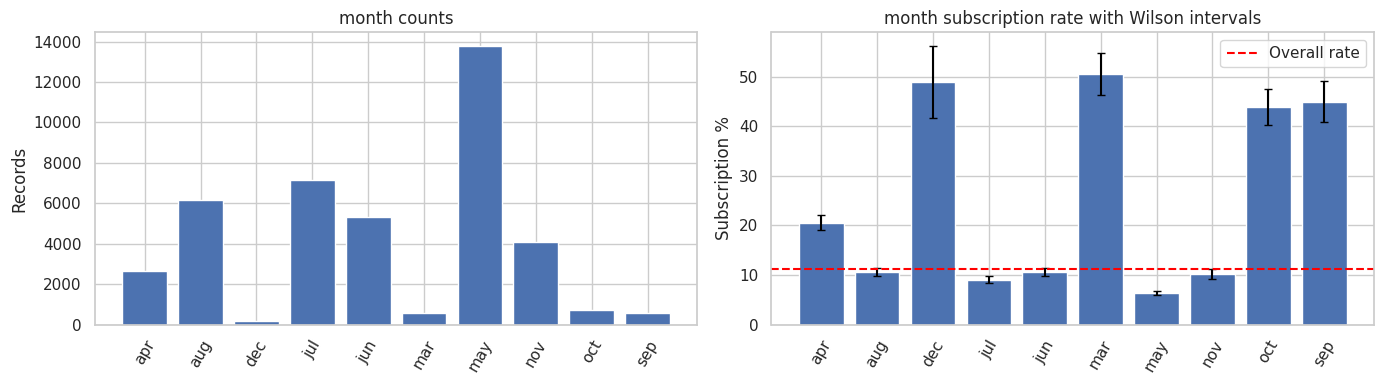

,n,subscriptions,rate_percent,lower95_percent,upper95_percent
group,,,,,
fri,7827,846,10.808739,10.139994,11.515936
mon,8514,847,9.948320,9.330486,10.602282
thu,8623,1045,12.118752,11.446751,12.824491
tue,8090,953,11.779975,11.095562,12.500669
wed,8134,949,11.667076,10.987438,12.382906


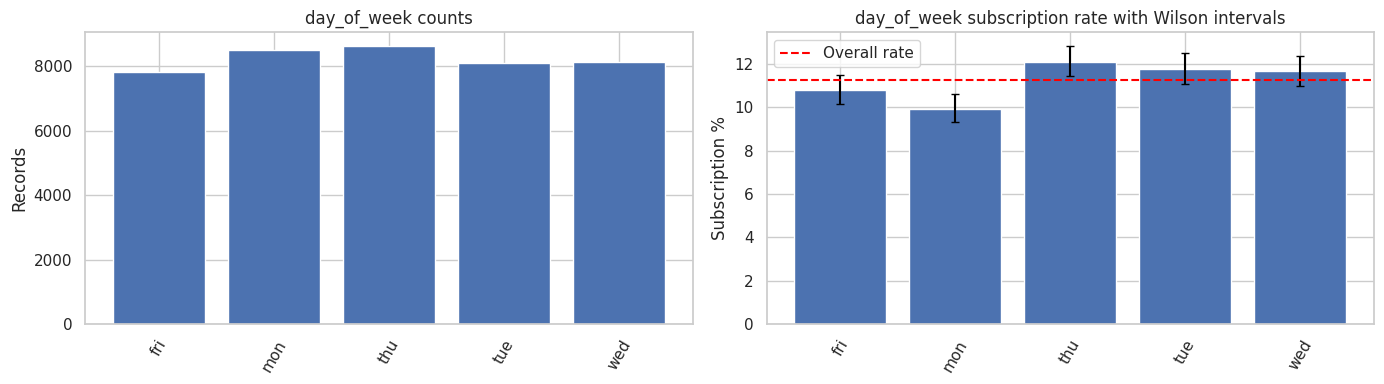

In [7]:
def rate_table(group):
    known = df.y.isin([0,1])
    temp = pd.DataFrame({'group':group, 'outcome':df.y}).loc[known]
    t=temp.groupby('group',observed=True,dropna=False)['outcome'].agg(n='size',subscriptions='sum')
    p=t.subscriptions/t.n; z=1.96
    center=(p+z*z/(2*t.n))/(1+z*z/t.n)
    half=z*np.sqrt(p*(1-p)/t.n+z*z/(4*t.n*t.n))/(1+z*z/t.n)
    t['rate_percent']=100*p; t['lower95_percent']=100*(center-half); t['upper95_percent']=100*(center+half)
    return t
for c in categorical:
    t=rate_table(df[c]); display(t)
    fig,axes=plt.subplots(1,2,figsize=(14,4))
    labels=t.index.astype(str)
    axes[0].bar(labels,t.n); axes[0].set_title(c+' counts'); axes[0].set_ylabel('Records')
    axes[1].bar(labels,t.rate_percent)
    axes[1].errorbar(range(len(t)),t.rate_percent,yerr=[t.rate_percent-t.lower95_percent,t.upper95_percent-t.rate_percent],fmt='none',color='black',capsize=3)
    axes[1].axhline(df.loc[df.y.isin([0,1]),'y'].mean()*100,color='red',linestyle='--',label='Overall rate')
    axes[1].set_title(c+' subscription rate with Wilson intervals'); axes[1].set_ylabel('Subscription %'); axes[1].legend()
    for ax in axes: ax.tick_params(axis='x',rotation=60)
    plt.tight_layout(); plt.show()


## Focus on age, campaign and pdays
Bins below are temporary plotting groups, not final feature engineering. Campaign tail groups retain all records in aggregated counts. Pdays is shown first as sentinel status, then actual day counts only among the 1,515 records with pdays != 999. This labelled plotting subset does not remove records from the dataset. Reporting recency averages including 999 would be misleading.


Actual-recency records: 1515


,n,subscriptions,rate_percent,lower95_percent,upper95_percent
group,,,,,
"[0.0, 25.0)",1068,256,23.970037,21.505885,26.620779
"[25.0, 35.0)",13686,1666,12.173024,11.635801,12.731476
"[35.0, 45.0)",13500,1168,8.651852,8.189301,9.137928
"[45.0, 55.0)",8704,753,8.651195,8.078695,9.260178
"[55.0, 65.0)",3567,484,13.568825,12.484084,14.731954
"[65.0, inf)",663,313,47.209653,43.436582,51.014874


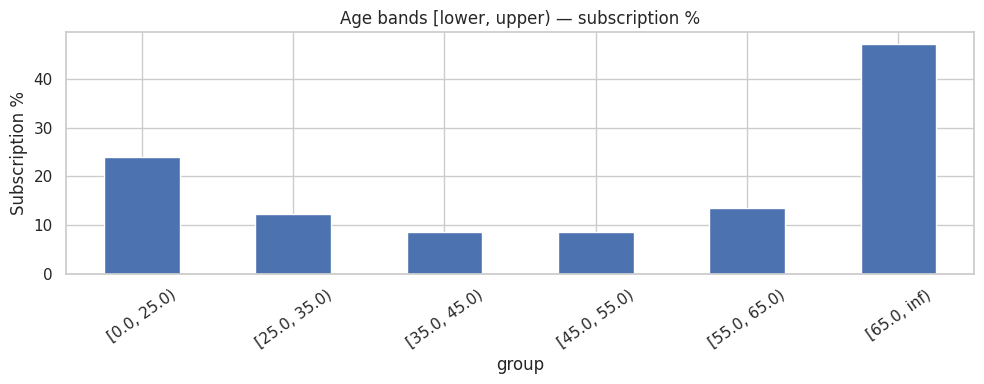

,n,subscriptions,rate_percent,lower95_percent,upper95_percent
group,,,,,
"(-0.001, 1.0]",17642,2300,13.037071,12.548241,13.541995
"(1.0, 2.0]",10570,1211,11.456954,10.863708,12.078206
"(2.0, 3.0]",5341,574,10.747051,9.944467,11.606062
"(3.0, 5.0]",4250,369,8.682353,7.872667,9.566666
"(5.0, 10.0]",2516,159,6.319555,5.433787,7.338508
"(10.0, inf]",869,27,3.107020,2.143969,4.482846


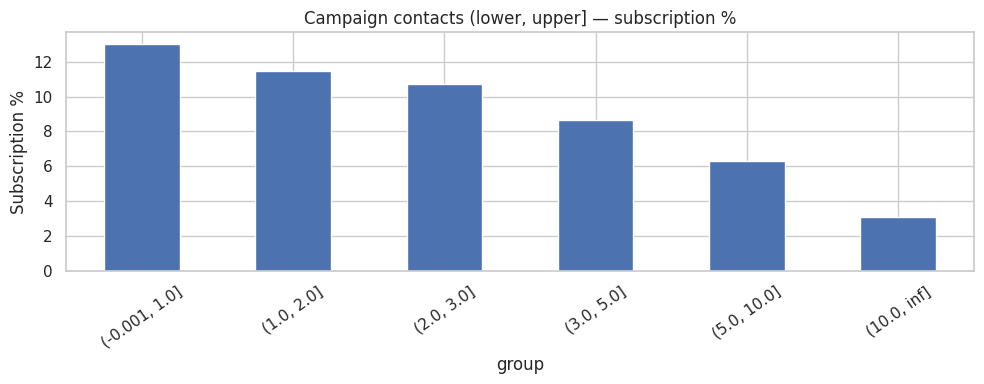

,n,subscriptions,rate_percent,lower95_percent,upper95_percent
group,,,,,
999: not previously contacted,39673,3673,9.258186,8.976900,9.547361
Actual recency available,1515,967,63.828383,61.376632,66.210182


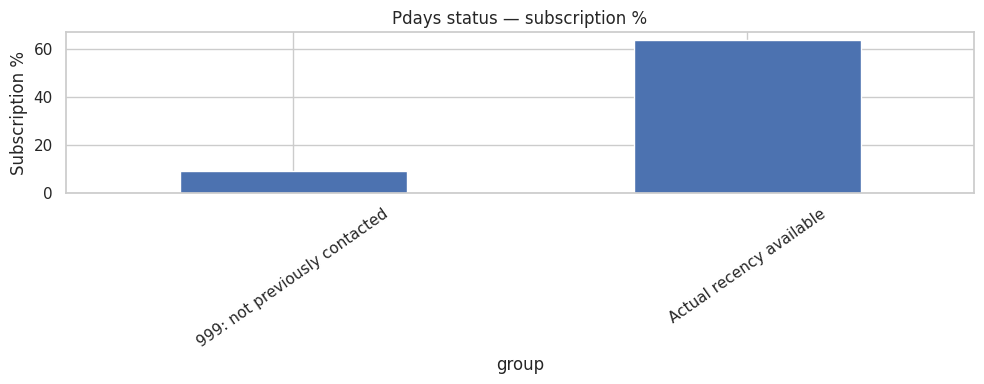

count    1515.000000
mean        6.014521
std         3.824906
min         0.000000
25%         3.000000
50%         6.000000
75%         7.000000
max        27.000000
Name: pdays, dtype: float64

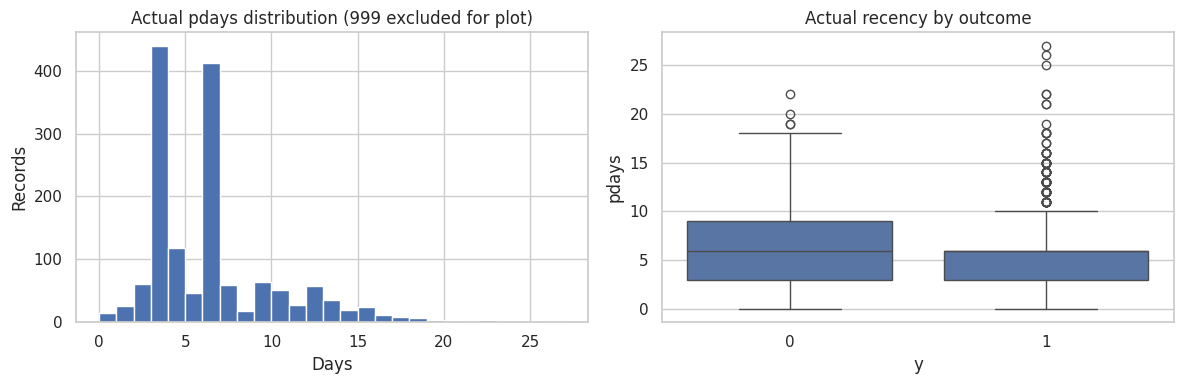

,n,subscriptions,rate_percent,lower95_percent,upper95_percent
group,,,,,
0,35563,3141,8.832213,8.541717,9.131603
1,4561,967,21.201491,20.039750,22.411703
2,754,350,46.419098,42.886453,49.988048
3,216,128,59.259259,52.600227,65.594692
4,70,38,54.285714,42.698053,65.427448
5,18,13,72.222222,49.126922,87.500431
6,5,3,60.000000,23.071993,88.238177
7,1,0,0.000000,0.000000,79.345671


In [8]:
age_groups=pd.cut(df.age,[0,25,35,45,55,65,np.inf],right=False)
campaign_groups=pd.cut(df.campaign,[0,1,2,3,5,10,np.inf],include_lowest=True)
pdays_status=df.pdays.eq(999).map({True:'999: not previously contacted',False:'Actual recency available'})
for label,groups in [('Age bands [lower, upper)',age_groups),('Campaign contacts (lower, upper]',campaign_groups),('Pdays status',pdays_status)]:
    t=rate_table(groups); display(t)
    ax=t.rate_percent.plot.bar(figsize=(10,4),title=label+' — subscription %',rot=35)
    ax.set_ylabel('Subscription %'); plt.tight_layout(); plt.show()
actual=df.loc[df.pdays.ne(999)]  # plot-only subset
print('Actual-recency records:',len(actual))
display(actual.pdays.describe())
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].hist(actual.pdays,bins=27); axes[0].set_title('Actual pdays distribution (999 excluded for plot)'); axes[0].set_xlabel('Days'); axes[0].set_ylabel('Records')
sns.boxplot(data=actual,x='y',y='pdays',ax=axes[1]); axes[1].set_title('Actual recency by outcome')
plt.tight_layout(); plt.show()
display(rate_table(df.previous))


## Socioeconomic indicators: distributions, rates and redundancy
**Observed:** Pearson correlations are approximately 0.972 between employment variation and Euribor, 0.945 between Euribor and number employed, and 0.907 between employment variation and number employed. Strong shared variation suggests redundancy and temporal context. This is not evidence that any variable should automatically be dropped.
**Hypothesis:** the economy and campaign period may partly explain group-rate differences. Without dates/year/client IDs, chronology and repeated-client structure cannot be verified. Month alone cannot recover year or exact order. Plotting groups for high-cardinality indicators are quantile ranges only; ties can reduce the number of groups.


,min,median,max,nunique
emp.var.rate,-3.400,1.100,1.400,10.0
cons.price.idx,92.201,93.749,94.767,26.0
cons.conf.idx,-50.800,-41.800,-26.900,26.0
euribor3m,0.634,4.857,5.045,316.0
nr.employed,4963.600,5191.000,5228.100,11.0


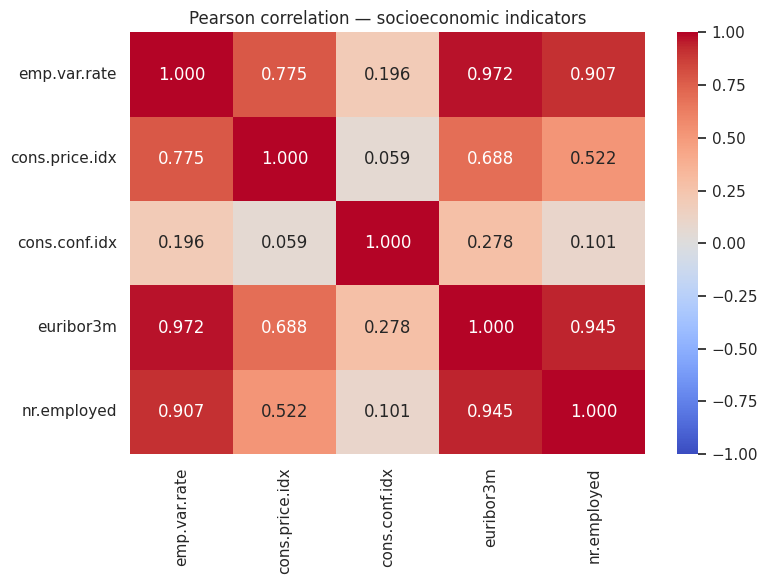

,n,subscriptions,rate_percent,lower95_percent,upper95_percent
group,,,,,
-3.4,1071,454,42.390289,39.462992,45.371983
-3.0,172,88,51.162791,43.748988,58.525787
-2.9,1663,594,35.718581,33.450885,38.052106
-1.8,9184,1461,15.908101,15.174333,16.670378
-1.7,773,403,52.134541,48.611086,55.636884
-1.1,635,301,47.401575,43.545107,51.289293
-0.2,10,1,10.000000,1.787575,40.415639
-0.1,3683,232,6.299213,5.559197,7.130299
1.1,7763,240,3.091588,2.729140,3.500439


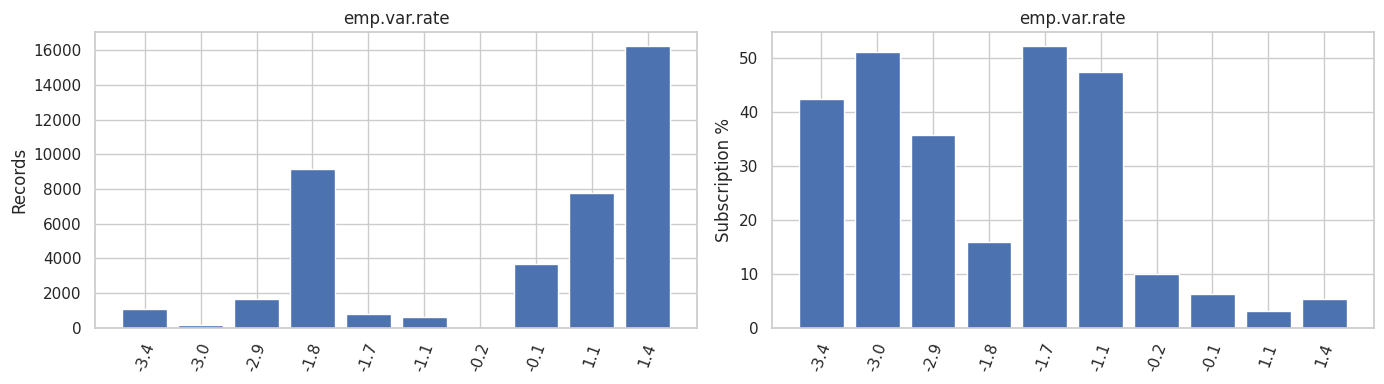

,n,subscriptions,rate_percent,lower95_percent,upper95_percent
group,,,,,
"(92.19999999999999, 92.893]",8277,1523,18.400387,17.580321,19.249771
"(92.893, 93.075]",3173,706,22.250236,20.837048,23.730538
"(93.075, 93.444]",9055,611,6.747653,6.249104,7.282887
"(93.444, 93.749]",174,97,55.747126,48.321951,62.924012
"(93.749, 93.918]",6964,571,8.199311,7.577748,8.866966
"(93.918, 93.994]",7763,240,3.091588,2.729140,3.500439
"(93.994, 94.199]",765,377,49.281046,45.750667,52.818609
"(94.199, 94.767]",5017,515,10.265099,9.455433,11.135569


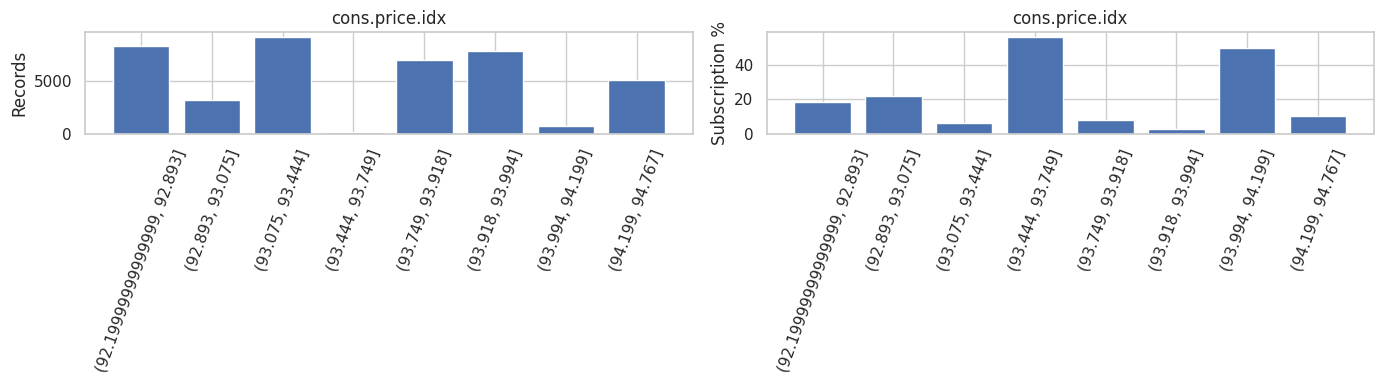

,n,subscriptions,rate_percent,lower95_percent,upper95_percent
group,,,,,
"(-50.800999999999995, -46.2]",8866,1243,14.019851,13.312715,14.758154
"(-46.2, -42.7]",6695,408,6.094100,5.545854,6.692704
"(-42.7, -41.8]",7990,378,4.730914,4.286760,5.218577
"(-41.8, -36.4]",9833,1221,12.417370,11.780176,13.083919
"(-36.4, -36.1]",5175,271,5.236715,4.662291,5.877549
"(-36.1, -26.9]",2629,1119,42.563712,40.685859,44.463266


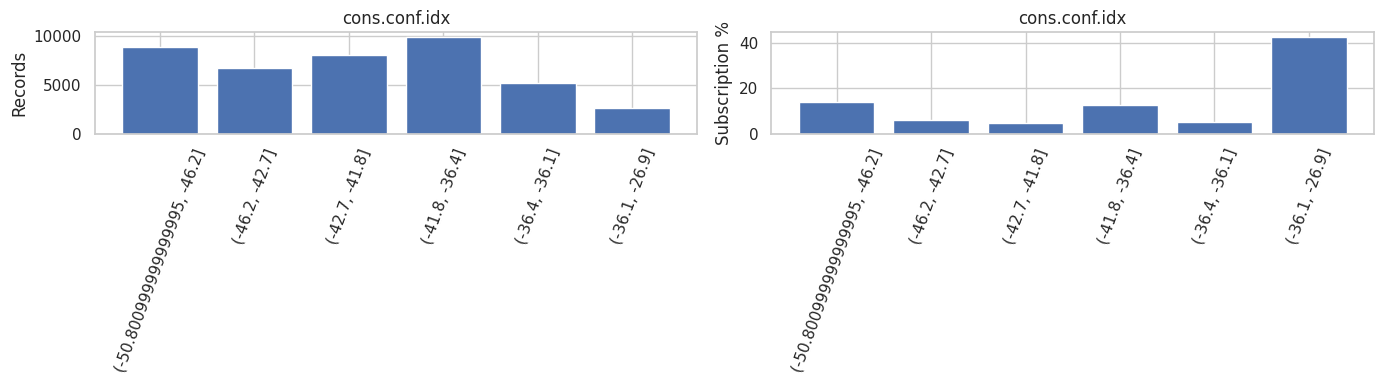

,n,subscriptions,rate_percent,lower95_percent,upper95_percent
group,,,,,
"(0.633, 1.25]",5314,2058,38.727889,37.426729,40.045334
"(1.25, 1.344]",5229,618,11.818703,10.971582,12.721885
"(1.344, 4.12]",5223,756,14.474440,13.546332,15.454769
"(4.12, 4.857]",6289,194,3.084751,2.685225,3.541558
"(4.857, 4.865]",3830,165,4.308094,3.709534,4.998223
"(4.865, 4.961]",5512,310,5.624093,5.046209,6.263789
"(4.961, 4.963]",5100,270,5.294118,4.712529,5.943005
"(4.963, 5.045]",4691,269,5.734385,5.104553,6.436659


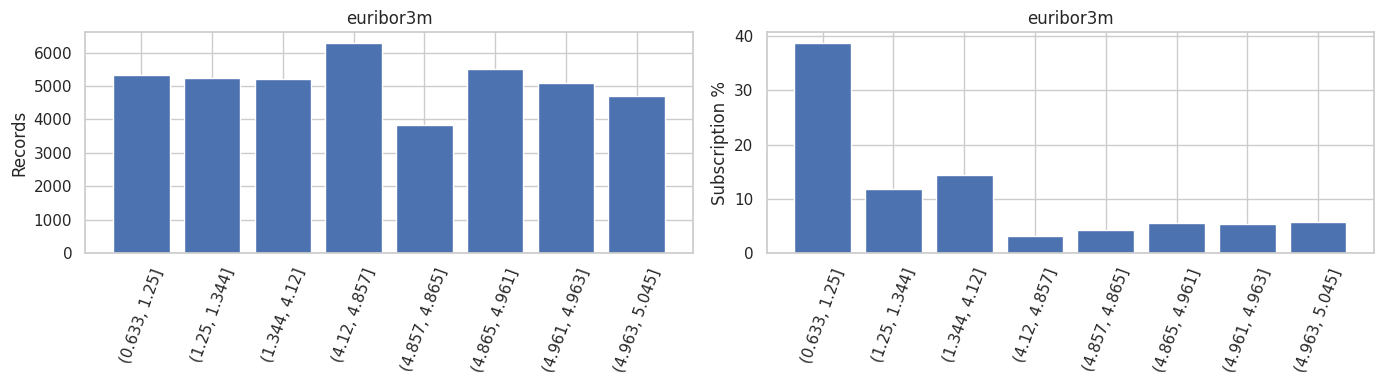

,n,subscriptions,rate_percent,lower95_percent,upper95_percent
group,,,,,
4963.6,635,301,47.401575,43.545107,51.289293
4991.6,773,403,52.134541,48.611086,55.636884
5008.7,650,369,56.769231,52.931969,60.526948
5017.5,1071,454,42.390289,39.462992,45.371983
5023.5,172,88,51.162791,43.748988,58.525787
5076.2,1663,594,35.718581,33.450885,38.052106
5099.1,8534,1092,12.795875,12.103843,13.521388
5176.3,10,1,10.000000,1.787575,40.415639
5191.0,7763,240,3.091588,2.729140,3.500439


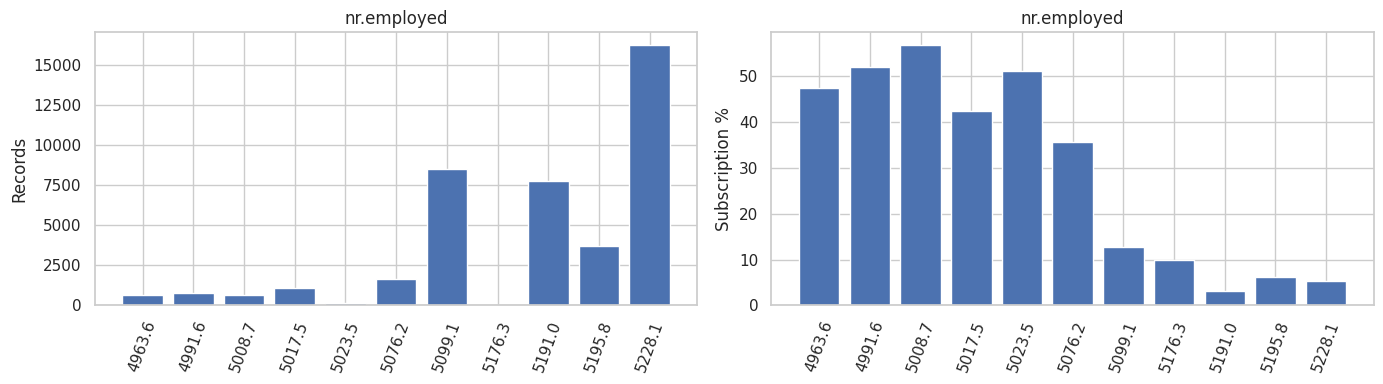

In [9]:
economic=['emp.var.rate','cons.price.idx','cons.conf.idx','euribor3m','nr.employed']
display(df[economic].agg(['min','median','max','nunique']).T)
fig,ax=plt.subplots(figsize=(8,6)); sns.heatmap(df[economic].corr(),annot=True,fmt='.3f',vmin=-1,vmax=1,cmap='coolwarm',ax=ax)
ax.set_title('Pearson correlation — socioeconomic indicators'); plt.tight_layout(); plt.show()
for c in economic:
    groups=df[c] if df[c].nunique()<=12 else pd.qcut(df[c],q=8,duplicates='drop')
    t=rate_table(groups); display(t)
    fig,axes=plt.subplots(1,2,figsize=(14,4))
    labels=t.index.astype(str)
    axes[0].bar(labels,t.n); axes[0].set_ylabel('Records')
    axes[1].bar(labels,t.rate_percent); axes[1].set_ylabel('Subscription %')
    for ax in axes: ax.set_title(c); ax.tick_params(axis='x',rotation=70)
    plt.tight_layout(); plt.show()


## Leakage and information availability
`duration` is measured during/after the last call and is unavailable for pre-call targeting. README recommends excluding it from realistic prediction; the EDA retains it only to inspect the leakage mechanism. Any later benchmark containing it must be separately labelled as post-call information. No feature is dropped here.
`campaign` includes the last contact, while month/day/contact describe the last call. The team must define whether prediction happens before a campaign, before a particular call, or after a call, and audit these fields against that time. Economic indicators require publication-time checks and can proxy historical periods. Previous-campaign attributes need confirmation that they were known at prediction time.
Identical or repeated clients across future splits could inflate evaluation. No client ID or full date is available; a random stratified split may mix periods and similar records. These are risks, not demonstrated leakage beyond the documented duration timing.


## Data-quality summary and candidate treatments
All treatments below are proposals. No treatment is applied. Supporting counts refer to the supplied file; flagging does not establish an error.

In [10]:
issues = [('README schema discrepancy', '41,188 × 20; 19 predictors versus README 20', 'Confirm intended schema with brief/data owner; do not invent a column'), ('Unknown information', 'job 330; marital 80; education 1,731; default 8,597; housing/loan 990 each', 'Compare explicit unknown categories versus imputation; preserve missingness signal'), ('Pdays structural sentinel', '999 in 39,673 (96.32%); actual days in 1,515', 'Consider prior-contact indicator plus recency conditional on contact; never treat 999 as ordinary elapsed days'), ('History-definition ambiguity', '4,110 previous>0 with pdays=999; 0 previous=0 with actual recency', 'Clarify scope and semantics before correction'), ('Duplicate records', '12 duplicates beyond first; no identical-predictor outcome conflicts', 'Validate provenance/client IDs; decide duplicate handling and split grouping'), ('Rare categories', 'default=1: 3; illiterate: 18', 'Review uncertainty and category grouping; no automatic merge/drop'), ('Extremes', 'age 17–98; campaign 1–56; duration 0–4,918', 'Verify valid ranges; consider robust methods only after approval'), ('Zero-duration calls', '4 records, all y=0', 'Keep for EDA; audit call completion; duration unavailable pre-call'), ('Economic redundancy', 'emp.var.rate–euribor3m r=0.972; euribor3m–nr.employed r=0.945', 'Discuss redundancy and temporal validation without selecting features now'), ('Limited calendar coverage', '10 months; Jan/Feb absent; no year/date/client ID', 'Clarify coverage; obtain time/client metadata if possible'), ('Outcome imbalance', '0:36,548 (88.73%); 1:4,640 (11.27%)', 'Approve metrics, costs, class weighting/resampling strategy within training partitions only'), ('Duration leakage', 'Last-call duration is unavailable before call (README)', 'Approve exclusion for pre-call model and any separate labelled benchmark'), ('Source brief unavailable', 'Requested DOCX not found', 'Supply and review project brief before finalizing downstream requirements')]
display(pd.DataFrame(issues,columns=['Issue','Supporting evidence','Possible treatment — approval required']))

,Issue,Supporting evidence,Possible treatment — approval required
0,README schema discrepancy,"41,188 × 20; 19 predictors versus README 20",Confirm intended schema with brief/data owner;...
1,Unknown information,"job 330; marital 80; education 1,731; default ...",Compare explicit unknown categories versus imp...
2,Pdays structural sentinel,"999 in 39,673 (96.32%); actual days in 1,515",Consider prior-contact indicator plus recency ...
3,History-definition ambiguity,"4,110 previous>0 with pdays=999; 0 previous=0 ...",Clarify scope and semantics before correction
4,Duplicate records,12 duplicates beyond first; no identical-predi...,Validate provenance/client IDs; decide duplica...
5,Rare categories,default=1: 3; illiterate: 18,Review uncertainty and category grouping; no a...
6,Extremes,"age 17–98; campaign 1–56; duration 0–4,918",Verify valid ranges; consider robust methods o...
7,Zero-duration calls,"4 records, all y=0",Keep for EDA; audit call completion; duration ...
8,Economic redundancy,emp.var.rate–euribor3m r=0.972; euribor3m–nr.e...,Discuss redundancy and temporal validation wit...
9,Limited calendar coverage,10 months; Jan/Feb absent; no year/date/client ID,Clarify coverage; obtain time/client metadata ...


## Decisions requiring team approval
1. Define prediction time, business objective and available inputs; approve exclusion of duration for pre-call use and any separate benchmark scope.
2. Resolve the 20-versus-21-column discrepancy and review the missing project brief; confirm campaign-history meanings and provenance.
3. Decide unknown handling per feature, including explicit categories, indicators or imputation; agree how to represent pdays=999. Decide what to do if unknown targets appear in future data.
4. Approve categorical encoding (including education ordering and calendar representation), rare-category grouping, numerical scaling and any transformations. None are selected here.
5. Decide duplicate handling after establishing record identity; verify unusual ranges before considering clipping or exclusion.
6. Approve validation design: held-out set and cross-validation; investigate temporal/client grouping versus stratification. README suggests five folds and a held-out set, but exact split proportions/design need agreement.
7. Approve metrics (including precision, recall, F1, ROC-AUC and PR-AUC), business error costs and threshold selection. Accuracy alone obscures imbalance.
8. Approve imbalance strategy (class weighting or any resampling), model families and tuning budget. Any later learned preprocessing/resampling must be fitted only on training folds.
9. Decide whether economic redundancy warrants feature selection and obtain indicator publication timing; consider limits on generalizing to future economic periods.

## Observed findings versus hypotheses
**Observed:** imbalance, documented unknowns/sentinels, exact duplicates, rare groups, extreme ranges, repeated economic values and strong economic correlations are directly supported above. All group rates are descriptive and include sample sizes.
**Hypotheses to investigate:** economic regime, age/customer mix and campaign selection may explain subscription-rate differences; history ambiguity may reflect scope differences rather than faulty records. None establishes causality, optimal contact strategy or future model performance.

## Integrity check
Verify that the original CSV bytes and the in-memory data remain unchanged. The notebook never writes to the source CSV.


In [11]:
assert df.equals(raw_snapshot), 'Data changed during EDA'
assert hashlib.sha256(DATA_PATH.read_bytes()).hexdigest() == source_sha256, 'Source CSV changed'
print('Verified: source bytes, observations, values and column order unchanged. No models or preprocessing fitted.')


Verified: source bytes, observations, values and column order unchanged. No models or preprocessing fitted.
